**Problem title: Predicting equipment operating condition from sensor**

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


Dataset creation

In [ ]:

data = {
    'Record': ['N01', 'N02', 'N03', 'N04', 'N05', 'N06',
               'N07', 'N08', 'N09', 'N10', 'N11', 'N12'],

    'Temperature': [58, 61, 55, 64, 60, 67,
                    72, 78, 75, 83, 69, 80],

    'Vibration': [1.2, 1.5, 1.0, 1.8, 1.4, 2.0,
                  3.8, 4.5, 4.1, 5.2, 3.4, 4.8],

    'Current': [4.1, 4.3, 3.9, 4.5, 4.2, 4.8,
                5.1, 5.6, 5.3, 6.0, 5.0, 5.8],

    'Condition': ['Normal'] * 6 + ['Fault'] * 6
}

df = pd.DataFrame(data)

print("Dataset:")
display(df)


Dataset:


,Record,Temperature,Vibration,Current,Condition
0,N01,58,1.2,4.1,Normal
1,N02,61,1.5,4.3,Normal
2,N03,55,1.0,3.9,Normal
3,N04,64,1.8,4.5,Normal
4,N05,60,1.4,4.2,Normal
5,N06,67,2.0,4.8,Normal
6,N07,72,3.8,5.1,Fault
7,N08,78,4.5,5.6,Fault
8,N09,75,4.1,5.3,Fault
9,N10,83,5.2,6.0,Fault


Dataset inspection

In [ ]:

print("First five records:")
display(df.head())

print("Dataset dimensions:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nClass distribution:")
print(df['Condition'].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())


First five records:


,Record,Temperature,Vibration,Current,Condition
0,N01,58,1.2,4.1,Normal
1,N02,61,1.5,4.3,Normal
2,N03,55,1.0,3.9,Normal
3,N04,64,1.8,4.5,Normal
4,N05,60,1.4,4.2,Normal


Dataset dimensions: (12, 5)

Data types:
Record          object
Temperature      int64
Vibration      float64
Current        float64
Condition       object
dtype: object

Class distribution:
Condition
Normal    6
Fault     6
Name: count, dtype: int64

Missing values:
Record         0
Temperature    0
Vibration      0
Current        0
Condition      0
dtype: int64

Duplicate records: 0


In [ ]:

print("Mean values:")
display(df.groupby('Condition')[
    ['Temperature', 'Vibration', 'Current']
].mean())

print("Standard Deviation:")
display(df.groupby('Condition')[
    ['Temperature', 'Vibration', 'Current']
].std())


Mean values:


,Temperature,Vibration,Current
Condition,,,
Fault,76.166667,4.300000,5.466667
Normal,60.833333,1.483333,4.300000


Standard Deviation:


,Temperature,Vibration,Current
Condition,,,
Fault,5.192944,0.663325,0.398330
Normal,4.262237,0.371035,0.316228


Visualization-Temperature distribution by motor condition

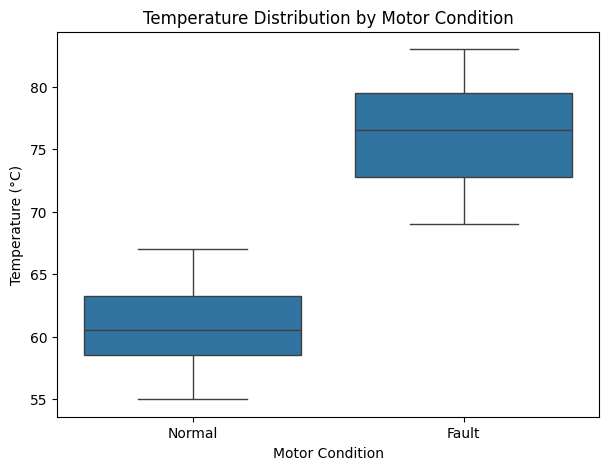

In [ ]:

plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x='Condition', y='Temperature')

plt.title('Temperature Distribution by Motor Condition')
plt.xlabel('Motor Condition')
plt.ylabel('Temperature (°C)')
plt.show()


Visualization-Vibration distribution by motor condition

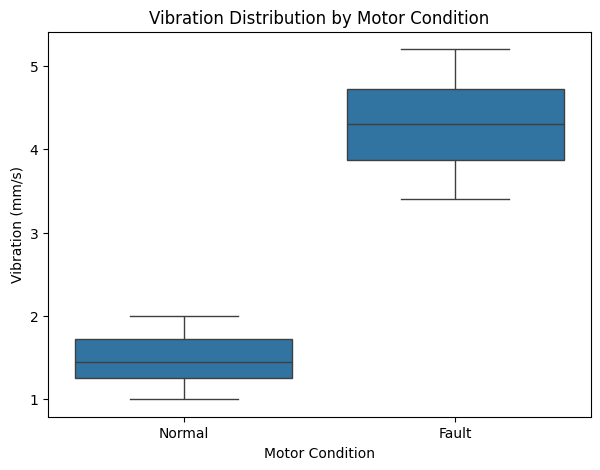

In [ ]:

plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x='Condition', y='Vibration')

plt.title('Vibration Distribution by Motor Condition')
plt.xlabel('Motor Condition')
plt.ylabel('Vibration (mm/s)')
plt.show()


Prepare features and target

In [ ]:

# Separate input features and target variable

X = df[['Temperature', 'Vibration', 'Current']]
y = df['Condition']

print("Input features:")
display(X.head())

print("\nTarget variable:")
print(y.head())


Input features:


,Temperature,Vibration,Current
0,58,1.2,4.1
1,61,1.5,4.3
2,55,1.0,3.9
3,64,1.8,4.5
4,60,1.4,4.2



Target variable:
0    Normal
1    Normal
2    Normal
3    Normal
4    Normal
Name: Condition, dtype: object


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.33,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training data shape: (8, 3)
Testing data shape: (4, 3)

Training class distribution:
Condition
Fault     4
Normal    4
Name: count, dtype: int64

Testing class distribution:
Condition
Normal    2
Fault     2
Name: count, dtype: int64


Train Gaussian Naïve Bayes

In [ ]:

# Create Gaussian Naive Bayes model

model = GaussianNB()

# Train the model
model.fit(X_train, y_train)

print("Gaussian Naive Bayes model trained successfully!")


Gaussian Naive Bayes model trained successfully!


In [ ]:

print("Class Priors:")
print(model.class_prior_)

print("\nClasses:")
print(model.classes_)

print("\nFeature Means:")
display(pd.DataFrame(
    model.theta_,
    index=model.classes_,
    columns=X.columns
))

print("\nFeature Variances:")
display(pd.DataFrame(
    model.var_,
    index=model.classes_,
    columns=X.columns
))


Class Priors:
[0.5 0.5]

Classes:
['Fault' 'Normal']

Feature Means:


,Temperature,Vibration,Current
Fault,76.25,4.300,5.45
Normal,59.50,1.375,4.20



Feature Variances:


,Temperature,Vibration,Current
Fault,9.1875,0.145000,0.0725
Normal,11.2500,0.091875,0.0500


In [ ]:

# Predict the test dataset

y_pred = model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

display(results)


,Actual,Predicted
0,Normal,Normal
1,Normal,Normal
2,Fault,Fault
3,Fault,Fault


In [ ]:

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label='Fault'
)

recall = recall_score(
    y_test, y_pred, pos_label='Fault'
)

f1 = f1_score(
    y_test, y_pred, pos_label='Fault'
)

print("MODEL EVALUATION")
print("------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


MODEL EVALUATION
------------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Classification Report:
              precision    recall  f1-score   support

       Fault       1.00      1.00      1.00         2
      Normal       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



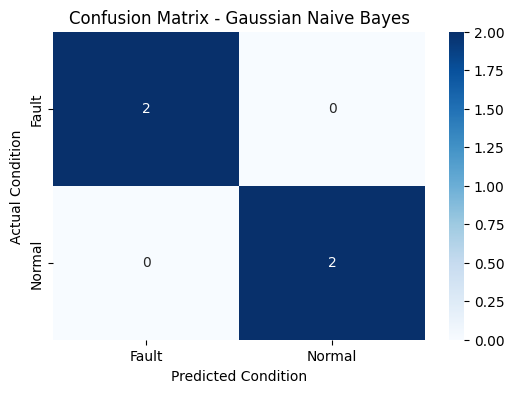

In [ ]:

# Generate confusion matrix

cm = confusion_matrix(
    y_test, y_pred,
    labels=['Fault', 'Normal']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fault', 'Normal'],
    yticklabels=['Fault', 'Normal']
)

plt.title('Confusion Matrix - Gaussian Naive Bayes')
plt.xlabel('Predicted Condition')
plt.ylabel('Actual Condition')
plt.show()


In [ ]:

# Create new observations

new_data = pd.DataFrame({
    'Temperature': [62, 77, 68],
    'Vibration': [1.6, 4.3, 2.8],
    'Current': [4.4, 5.7, 4.9]
}, index=['T01', 'T02', 'T03'])

# Predict classes
new_predictions = model.predict(new_data)

# Calculate posterior probabilities
probabilities = model.predict_proba(new_data)

# Display results
prediction_results = pd.DataFrame({
    'Predicted Condition': new_predictions,
    'P(Fault)': probabilities[:, 0],
    'P(Normal)': probabilities[:, 1]
}, index=new_data.index)

display(prediction_results)


,Predicted Condition,P(Fault),P(Normal)
T01,Normal,1.817306e-19,1.000000e+00
T02,Fault,1.000000e+00,2.705056e-36
T03,Fault,9.950359e-01,4.964135e-03


The model was trained using 8 observations and tested using 4 observations. It achieved 100% accuracy, precision, recall and F1-score on the test dataset. The model successfully predicted the operating conditions of three unseen observations. The results demonstrate that Gaussian Naïve Bayes  model is suitable for a preliminary alerting prototype.However, further validation using a larger and more diverse dataset is required before real-world deployment.